## Debug · distribución en 2019: GY real vs GBLUP vs red sola

Entrena el modelo `gblup_residual` con **2017+2018** y predice **2019**. Grafica tres distribuciones:
el GY observado, la predicción de **GBLUP** (base lineal) y la de **solo la red** (la componente
neuronal, que predice el residual `GY − ŷ_GBLUP`).

**Ojo con la escala:** la red predice el *residual*, así que su distribución está centrada cerca de
**0**, en otra escala que GY real y GBLUP (~6–7) — aparece como un pico a la izquierda. Sirve para ver
cuánta señal (dispersión) mete la red, y el *shift* de media / shrinkage de GBLUP frente a la verdad.
Pegá el `<sweep_id>` en `RESID_SWEEP` para usar los HP del sweep; sin eso cae a los HP del config base.

HP del sweep (run 7ltwjhxe, pearson_r_mean val2018 = 0.3813)
  GBLUP       : pearson=0.3145  rmse=1.302  r2=-0.664  mean=7.132  std=0.760
  red (resid) : pearson_vs_GY=-0.0147  mean=0.154  std=0.532   (escala de RESIDUAL, ~0)
  GY real     : mean=6.370  std=1.009  n=722


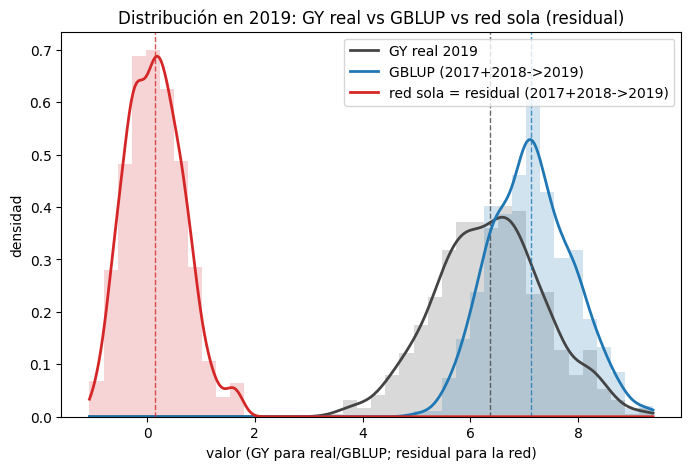

In [3]:
import os, sys, pathlib
import numpy as np
import matplotlib.pyplot as plt

# Raíz del repo (sube hasta encontrar src/) -> imports y rutas de datos robustos al cwd.
ROOT = pathlib.Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("WANDB_MODE", "offline")

from src.utils.config import load_config, set_nested
from src.data.loader import load_dataset
from src.eval.splits import fixed_temporal_split
from src.models.registry import build_model
from src.eval.metrics import pearson_r, rmse, r2

RESID_BASE  = ROOT / "configs" / "exp_gblup_residual_2017_to_2018.yaml"
RESID_SWEEP = "oromagnoli-/maze-genomic-pred/o4kl9qbz"   # gblup_residual

# 1) Datos + split de REPORTE: train 2017+2018 -> val 2019 (2020 sellado).
cfg = load_config(str(RESID_BASE))
ds  = load_dataset(str(ROOT / cfg["data"]["geno_csv"]), str(ROOT / cfg["data"]["pheno_csv"]))
arr = ds.to_modeling_arrays(target=cfg["data"]["target"], env=cfg["data"]["env"])
(tr, va) = fixed_temporal_split(arr.year, arr.line_id, val_year=2019,
                                train_years=[2017, 2018], holdout_test_year=2020)[0]
Xtr, ytr, Xva, ytrue = arr.X[tr], arr.y[tr], arr.X[va], arr.y[va]
cfg["cv"] = {"scheme": "fixed_temporal", "val_year": 2019, "train_years": [2017, 2018],
             "holdout_test_year": 2020, "enforce_disjoint_lines": True}

# 2) HP de la red buscados en val 2018 (mejor del sweep); si no hay sweep, usa el config base.
try:
    from src.training.sweep import best_run_from_sweep
    ov, p2018, rid = best_run_from_sweep(RESID_SWEEP)
    for k, v in ov.items():
        set_nested(cfg, k, v)
    print(f"HP del sweep (run {rid}, pearson_r_mean val2018 = {p2018:.4f})")
except Exception as e:
    print(f"[warn] sin sweep ({type(e).__name__}); uso los HP del config base.")

# 3) Entreno el modelo (GBLUP + red) con 2017+2018 y predigo 2019 (2019 NO entra al ajuste).
model = build_model(cfg)
model.set_fit_context(year=arr.year[tr], line_id=arr.line_id[tr])
model.fit(Xtr, ytr)
y_gblup = model.gblup.predict(Xva)   # base lineal GBLUP (escala de GY)
y_red   = model.mlp.predict(Xva)     # SOLO la red: predice el residual (GY - y_gblup), centrado ~0

print(f"  {'GBLUP':12s}: pearson={pearson_r(ytrue, y_gblup):.4f}  rmse={rmse(ytrue, y_gblup):.3f}  "
      f"r2={r2(ytrue, y_gblup):.3f}  mean={y_gblup.mean():.3f}  std={y_gblup.std():.3f}")
print(f"  {'red (resid)':12s}: pearson_vs_GY={pearson_r(ytrue, y_red):.4f}  "
      f"mean={y_red.mean():.3f}  std={y_red.std():.3f}   (escala de RESIDUAL, ~0)")
print(f"  {'GY real':12s}: mean={ytrue.mean():.3f}  std={ytrue.std():.3f}  n={len(ytrue)}")

# 4) Distribuciones superpuestas. OJO: la red predice el RESIDUAL (GY - y_gblup), así que va en
#    otra escala (centrada ~0) que GY real y GBLUP (~6-7); por eso aparece como un pico a la izq.
series = [("GY real 2019", ytrue, "#444444"),
          ("GBLUP (2017+2018->2019)", y_gblup, "#1f77b4"),
          ("red sola = residual (2017+2018->2019)", y_red, "#d62728")]
lo = min(float(s.min()) for _, s, _ in series)
hi = max(float(s.max()) for _, s, _ in series)
grid = np.linspace(lo, hi, 300)
fig, ax = plt.subplots(figsize=(8, 5))
for label, s, c in series:
    ax.hist(s, bins=40, range=(lo, hi), density=True, alpha=0.20, color=c)
    try:
        from scipy.stats import gaussian_kde
        ax.plot(grid, gaussian_kde(s)(grid), color=c, lw=2, label=label)
    except Exception:
        ax.plot([], [], color=c, lw=2, label=label)
    ax.axvline(float(np.mean(s)), color=c, ls="--", lw=1, alpha=0.8)
ax.set_xlabel("valor (GY para real/GBLUP; residual para la red)"); ax.set_ylabel("densidad")
ax.set_title("Distribución en 2019: GY real vs GBLUP vs red sola (residual)")
ax.legend()
plt.show()

HP del sweep (run i7h7516k, pearson_r_mean val2018 = 0.3953)
  GBLUP       : pearson=0.3145  rmse=1.302  r2=-0.664  mean=7.132  std=0.760
  red (resid) : pearson_vs_GY=-0.0555  mean=0.131  std=0.266   (escala de RESIDUAL, ~0)
  GY real     : mean=6.370  std=1.009  n=722


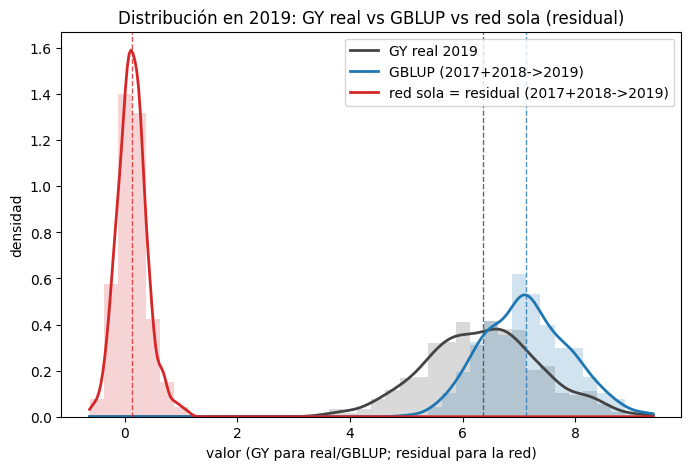

In [4]:
import os, sys, pathlib
import numpy as np
import matplotlib.pyplot as plt

# Raíz del repo (sube hasta encontrar src/) -> imports y rutas de datos robustos al cwd.
ROOT = pathlib.Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("WANDB_MODE", "offline")

from src.utils.config import load_config, set_nested
from src.data.loader import load_dataset
from src.eval.splits import fixed_temporal_split
from src.models.registry import build_model
from src.eval.metrics import pearson_r, rmse, r2

RESID_BASE  = ROOT / "configs" / "exp_gblup_residual_2017_to_2018.yaml"
RESID_SWEEP = "oromagnoli-/maze-genomic-pred/yj2h9x3g"   # red con pearson_mse_loss

# 1) Datos + split de REPORTE: train 2017+2018 -> val 2019 (2020 sellado).
cfg = load_config(str(RESID_BASE))
ds  = load_dataset(str(ROOT / cfg["data"]["geno_csv"]), str(ROOT / cfg["data"]["pheno_csv"]))
arr = ds.to_modeling_arrays(target=cfg["data"]["target"], env=cfg["data"]["env"])
(tr, va) = fixed_temporal_split(arr.year, arr.line_id, val_year=2019,
                                train_years=[2017, 2018], holdout_test_year=2020)[0]
Xtr, ytr, Xva, ytrue = arr.X[tr], arr.y[tr], arr.X[va], arr.y[va]
cfg["cv"] = {"scheme": "fixed_temporal", "val_year": 2019, "train_years": [2017, 2018],
             "holdout_test_year": 2020, "enforce_disjoint_lines": True}

# 2) HP de la red buscados en val 2018 (mejor del sweep); si no hay sweep, usa el config base.
try:
    from src.training.sweep import best_run_from_sweep
    ov, p2018, rid = best_run_from_sweep(RESID_SWEEP)
    for k, v in ov.items():
        set_nested(cfg, k, v)
    print(f"HP del sweep (run {rid}, pearson_r_mean val2018 = {p2018:.4f})")
except Exception as e:
    print(f"[warn] sin sweep ({type(e).__name__}); uso los HP del config base.")

# 3) Entreno el modelo (GBLUP + red) con 2017+2018 y predigo 2019 (2019 NO entra al ajuste).
model = build_model(cfg)
model.set_fit_context(year=arr.year[tr], line_id=arr.line_id[tr])
model.fit(Xtr, ytr)
y_gblup = model.gblup.predict(Xva)   # base lineal GBLUP (escala de GY)
y_red   = model.mlp.predict(Xva)     # SOLO la red: predice el residual (GY - y_gblup), centrado ~0

print(f"  {'GBLUP':12s}: pearson={pearson_r(ytrue, y_gblup):.4f}  rmse={rmse(ytrue, y_gblup):.3f}  "
      f"r2={r2(ytrue, y_gblup):.3f}  mean={y_gblup.mean():.3f}  std={y_gblup.std():.3f}")
print(f"  {'red (resid)':12s}: pearson_vs_GY={pearson_r(ytrue, y_red):.4f}  "
      f"mean={y_red.mean():.3f}  std={y_red.std():.3f}   (escala de RESIDUAL, ~0)")
print(f"  {'GY real':12s}: mean={ytrue.mean():.3f}  std={ytrue.std():.3f}  n={len(ytrue)}")

# 4) Distribuciones superpuestas. OJO: la red predice el RESIDUAL (GY - y_gblup), así que va en
#    otra escala (centrada ~0) que GY real y GBLUP (~6-7); por eso aparece como un pico a la izq.
series = [("GY real 2019", ytrue, "#444444"),
          ("GBLUP (2017+2018->2019)", y_gblup, "#1f77b4"),
          ("red sola = residual (2017+2018->2019)", y_red, "#d62728")]
lo = min(float(s.min()) for _, s, _ in series)
hi = max(float(s.max()) for _, s, _ in series)
grid = np.linspace(lo, hi, 300)
fig, ax = plt.subplots(figsize=(8, 5))
for label, s, c in series:
    ax.hist(s, bins=40, range=(lo, hi), density=True, alpha=0.20, color=c)
    try:
        from scipy.stats import gaussian_kde
        ax.plot(grid, gaussian_kde(s)(grid), color=c, lw=2, label=label)
    except Exception:
        ax.plot([], [], color=c, lw=2, label=label)
    ax.axvline(float(np.mean(s)), color=c, ls="--", lw=1, alpha=0.8)
ax.set_xlabel("valor (GY para real/GBLUP; residual para la red)"); ax.set_ylabel("densidad")
ax.set_title("Distribución en 2019: GY real vs GBLUP vs red sola (residual)")
ax.legend()
plt.show()

## Debug · calibrar el aporte de la red: ŷ = ŷ_GBLUP + β·ŷ_red (+ γ)

Calibra cuánto confiar en la red. Se estiman `β, γ` por OLS en **val 2018** (entrenando en 2017) sobre
`GY − ŷ_GBLUP ~ ŷ_red`, y se **aplican al reporte 2019** (entrenando en 2017+2018); 2019 no entra a la
estimación. `β` es un shrinkage del aporte de la red: con **`β ≥ 0`** la red solo suma, y si no ayuda
(β=0) recuperás GBLUP exacto → *nunca degrada*. El `γ` (corrección de nivel) se muestra como
diagnóstico pero **no transfiere** entre años (el shift de media depende de qué años entrenan el
GBLUP, distinto en calibración vs reporte), así que la variante robusta para el Pearson va **sin γ**.

In [1]:
import os, sys, pathlib
import numpy as np

ROOT = pathlib.Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("WANDB_MODE", "offline")

from src.utils.config import load_config, set_nested
from src.data.loader import load_dataset
from src.eval.splits import fixed_temporal_split
from src.models.registry import build_model
from src.eval.metrics import pearson_r, rmse, r2

RESID_BASE  = ROOT / "configs" / "exp_gblup_residual_2017_to_2018.yaml"
RESID_SWEEP = "oromagnoli-/maze-genomic-pred/o4kl9qbz"  

_cfg0 = load_config(str(RESID_BASE))
_ds   = load_dataset(str(ROOT / _cfg0["data"]["geno_csv"]), str(ROOT / _cfg0["data"]["pheno_csv"]))
_arr  = _ds.to_modeling_arrays(target=_cfg0["data"]["target"], env=_cfg0["data"]["env"])

# HP de la red: mejor del sweep (val 2018) o config base si todavia no hay sweep.
_overrides = {}
try:
    from src.training.sweep import best_run_from_sweep
    _overrides, _p2018, _rid = best_run_from_sweep(RESID_SWEEP)
    print(f"HP del sweep (run {_rid}, pearson_r_mean val2018 = {_p2018:.4f})")
except Exception as e:
    print(f"[warn] sin sweep ({type(e).__name__}); uso los HP del config base.")

def fit_residual(train_years, val_year):
    """Entrena gblup_residual en train_years y predice val_year. Devuelve (y_true, y_gblup, y_red)."""
    cfg = load_config(str(RESID_BASE))
    for k, v in _overrides.items():
        set_nested(cfg, k, v)
    (tr, va) = fixed_temporal_split(_arr.year, _arr.line_id, val_year=val_year,
                                    train_years=list(train_years), holdout_test_year=2020)[0]
    m = build_model(cfg)
    m.set_fit_context(year=_arr.year[tr], line_id=_arr.line_id[tr])
    m.fit(_arr.X[tr], _arr.y[tr])
    return _arr.y[va], m.gblup.predict(_arr.X[va]), m.mlp.predict(_arr.X[va])

# 1) Estima beta, gamma en val 2018 (entrenando en 2017): OLS de (GY - y_gblup) sobre y_red.
yt18, ygb18, yred18 = fit_residual([2017], 2018)
beta, gamma = np.linalg.lstsq(np.column_stack([yred18, np.ones_like(yred18)]),
                              yt18 - ygb18, rcond=None)[0]
beta_pos = max(0.0, float(beta))   # la red solo suma: si no ayuda en 2018, beta=0 -> GBLUP exacto
print(f"\ncalibracion en 2018:  beta_ols={beta:+.4f}   beta>=0={beta_pos:.4f}   gamma={gamma:+.4f}")

# 2) Aplica al reporte 2019 (entrenando en 2017+2018). 2019 NO entro a estimar beta,gamma.
yt19, ygb19, yred19 = fit_residual([2017, 2018], 2019)
variantes = {
    "GBLUP (base)":      ygb19,
    "GBLUP + red (b=1)": ygb19 + yred19,                  # stacking rigido (lo de hoy)
    "GBLUP + b>=0 . red": ygb19 + beta_pos * yred19,      # robusta (Pearson), sin gamma
    "GBLUP + b.red+gamma": ygb19 + beta * yred19 + gamma, # con nivel (gamma no transfiere)
}
print("\nReporte en val 2019 (Pearson = portada; RMSE/R2 de apoyo):")
for name, yp in variantes.items():
    print(f"  {name:20s}: pearson={pearson_r(yt19, yp):.4f}  rmse={rmse(yt19, yp):.3f}  r2={r2(yt19, yp):.3f}")

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from C:\Users\MODDE\.netrc.


HP del sweep (run 7ltwjhxe, pearson_r_mean val2018 = 0.3813)

calibracion en 2018:  beta_ols=+1.0966   beta>=0=1.0966   gamma=+2.2250

Reporte en val 2019 (Pearson = portada; RMSE/R2 de apoyo):
  GBLUP (base)        : pearson=0.3145  rmse=1.302  r2=-0.664
  GBLUP + red (b=1)   : pearson=0.2516  rmse=1.495  r2=-1.196
  GBLUP + b>=0 . red  : pearson=0.2429  rmse=1.523  r2=-1.279
  GBLUP + b.red+gamma : pearson=0.2429  rmse=3.378  r2=-10.210


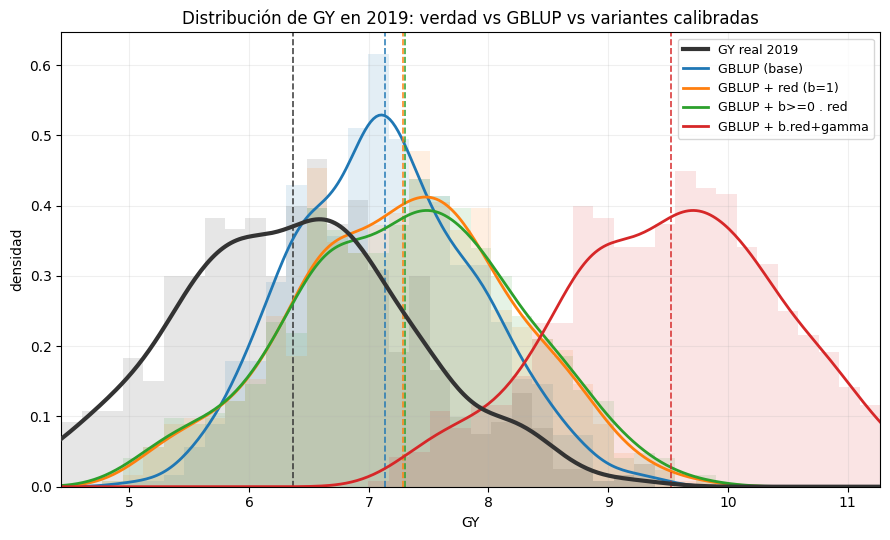

In [2]:
import matplotlib.pyplot as plt

to_plot = {"GY real 2019": yt19, **variantes}                # incluye la verdad como referencia
allv = np.concatenate([np.asarray(v, float).ravel() for v in to_plot.values()])
lo, hi = np.percentile(allv, [0.5, 99.5])                    # rango robusto (ignora outliers)
grid = np.linspace(lo, hi, 300)

cmap = plt.get_cmap("tab10")                                 # un color FIJO por serie
colors = {name: ("#333333" if i == 0 else cmap((i - 1) % 10))
          for i, name in enumerate(to_plot)}
try:
    from scipy.stats import gaussian_kde
    _has_kde = True
except Exception:
    _has_kde = False

fig, ax = plt.subplots(figsize=(9, 5.5))
for name, yp in to_plot.items():
    yp = np.asarray(yp, float).ravel()
    c = colors[name]
    ref = name == "GY real 2019"
    ax.hist(yp, bins=40, range=(lo, hi), density=True, alpha=0.12, color=c)
    if _has_kde and np.std(yp) > 1e-9:
        ax.plot(grid, gaussian_kde(yp)(grid), color=c, lw=3 if ref else 2,
                label=name, zorder=3 if ref else 2)
    else:
        ax.plot([], [], color=c, lw=2, label=name)
    ax.axvline(yp.mean(), color=c, ls="--", lw=1.2, alpha=0.9)

ax.set_xlim(lo, hi)
ax.set_xlabel("GY"); ax.set_ylabel("densidad")
ax.set_title("Distribución de GY en 2019: verdad vs GBLUP vs variantes calibradas")
ax.legend(fontsize=9); ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()